# Car Listings – Feature Engineering & KPI Visualizations

Builds on `cleaned_imputed.csv` (output of the cleaning/imputation notebook).

**Steps:**
1. Load cleaned data
2. Feature engineering (age, usage, power-to-weight, discount %, feature counts, popularity encodings, flags)
3. KPI visualizations (price drivers, depreciation, mix by fuel/transmission, discounts, correlations)
4. Save the feature-engineered dataset


## 1. Load cleaned data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 60)


df = pd.read_csv("Clean_data.csv")
print(f"Loaded: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(3)

Loaded: 37708 rows, 58 columns


,Unnamed: 0,myear,body,transmission,fuel,km,ip,threesixty,dvn,oem,model,variant,City,listed_price,discountValue,utype,carType,top_features,comfort_features,interior_features,exterior_features,safety_features,Color,Engine Type,No of Cylinder,Valves per Cylinder,Valve Configuration,Turbo Charger,Super Charger,Length,Width,Height,Wheel Base,Front Tread,Rear Tread,Kerb Weight,Gear Box,Drive Type,Seats,Steering Type,Turning Radius,Front Brake Type,Rear Brake Type,Top Speed,Acceleration,Tyre Type,Doors,Cargo Volume,model_type_new,state,exterior_color,owner_type,Fuel Suppy System,Alloy Wheel Size,Max Power Delivered,Max Power At,Max Torque Delivered,Max Torque At
0,0,2016,hatchback,manual,cng,69162.0,0,False,maruti wagon r lxi cng,maruti,maruti wagon r,lxi cng,lucknow,370000.0,0,dealer,corporate,"['power steering', 'power windows front', 'air...","['power steering', 'power windows front', 'rem...","['air conditioner', 'heater', 'digital odomete...","['adjustable head lights', 'manually adjustabl...","['centeral locking', 'child safety locks', 'da...",silver,k10b engine,3.0,4.0,dohc,False,False,3599.0,1495.0,1700.0,2400.0,1295.0,1290.0,960.0,5 speed,fwd,5.0,power,4.6,ventilated disc,drum,137.0,15.90,tubeless,5.0,180.0,used,uttar pradesh,silver,first,Multi-Point Fuel Injection,13.0,58.16,6200.0,77.0,3500.0
1,1,2015,hatchback,manual,cng,45864.0,0,False,maruti celerio green vxi,maruti,maruti celerio,green vxi,mumbai,365000.0,0,dealer,corporate,"['power steering', 'power windows front', 'air...","['power steering', 'power windows front', 'pow...","['air conditioner', 'heater', 'digital odomete...","['adjustable head lights', 'manually adjustabl...","['centeral locking', 'child safety locks', 'da...",grey,k10b engine,3.0,4.0,dohc,False,False,3600.0,1600.0,1560.0,2425.0,1420.0,1410.0,915.0,5 speed,fwd,5.0,power,4.7,ventilated disc,drum,150.0,15.05,tubeless radial,5.0,235.0,used,maharashtra,grey,first,Gasoline Port Injection,15.0,58.20,6000.0,78.0,3500.0
2,2,2015,sedan,manual,cng,81506.0,0,False,honda amaze s plus i-vtec,honda,honda amaze,s plus i-vtec,new delhi,421000.0,0,dealer,corporate,"['power steering', 'power windows front', 'air...","['power steering', 'power windows front', 'pow...","['air conditioner', 'heater', 'adjustable stee...","['adjustable head lights', 'power adjustable e...","['centeral locking', 'power door locks', 'chil...",silver,i-vtec petrol engine,4.0,4.0,sohc,False,False,3990.0,1680.0,1505.0,2405.0,1480.0,1465.0,950.0,5 speed,fwd,5.0,power,4.5,disc,drum,160.0,15.00,tubeless radial,4.0,400.0,used,delhi,silver,second,Multi-Point Fuel Injection,14.0,86.70,6000.0,109.0,4500.0


## 2. Feature engineering

### 2.1 Age & usage features
- `car_age` = current year − manufacturing year
- `km_per_year` = km driven / car age (usage intensity; a proxy for how hard the car was used)

In [3]:
CURRENT_YEAR = 2026

df['car_age'] = CURRENT_YEAR - df['myear']
df['car_age'] = df['car_age'].clip(lower=1)  # avoid divide-by-zero for brand-new cars
df['km_per_year'] = (df['km'] / df['car_age']).round(0)

df[['myear', 'car_age', 'km', 'km_per_year']].describe()

,myear,car_age,km,km_per_year
count,37708.000000,37708.000000,3.770800e+04,37708.000000
mean,2015.568474,10.431526,6.217220e+04,5884.822717
std,3.779942,3.779942,4.326166e+04,3829.392243
min,1983.000000,3.000000,1.010000e+02,19.000000
25%,2013.000000,8.000000,3.176175e+04,3535.750000
50%,2016.000000,10.000000,5.678150e+04,5333.000000
75%,2018.000000,13.000000,8.337050e+04,7500.000000
max,2023.000000,43.000000,1.466000e+06,244333.000000


### 2.2 Performance & value features
- `power_to_weight` = Max Power Delivered (bhp) / Kerb Weight (kg) — higher = sportier
- `discount_pct` = discount as a % of the pre-discount price

In [4]:
df['power_to_weight'] = (df['Max Power Delivered'] / df['Kerb Weight']).round(4)

pre_discount_price = df['listed_price'] + df['discountValue']
df['discount_pct'] = (df['discountValue'] / pre_discount_price * 100).round(2)

df[['Max Power Delivered', 'Kerb Weight', 'power_to_weight', 'discountValue', 'listed_price', 'discount_pct']].describe()

,Max Power Delivered,Kerb Weight,power_to_weight,discountValue,listed_price,discount_pct
count,37708.000000,37708.000000,37708.000000,37708.000000,3.770800e+04,37708.000000
mean,102.520552,1190.817320,0.085677,73.485759,7.830354e+05,0.004170
std,42.645347,347.487857,0.020849,2809.684420,1.124570e+06,0.135083
min,10.800000,451.000000,0.023900,0.000000,1.196300e+04,0.000000
25%,74.020000,935.000000,0.072700,0.000000,3.199990e+05,0.000000
50%,88.500000,1066.000000,0.084800,0.000000,5.250000e+05,0.000000
75%,118.350000,1305.000000,0.095400,0.000000,8.520170e+05,0.000000
max,769.310000,2962.000000,0.490000,200000.000000,9.551953e+07,8.600000


### 2.3 Feature-richness counts

`top_features`, `comfort_features`, `interior_features`, `exterior_features`, `safety_features`
are stored as Python-list-looking strings. Parse them and count how many features
each car has in each category — more features usually signals a higher trim / higher price.

In [5]:
feature_cols = ['top_features', 'comfort_features', 'interior_features',
                'exterior_features', 'safety_features']

def count_features(s):
    try:
        lst = ast.literal_eval(s) if isinstance(s, str) else []
        return len(lst)
    except (ValueError, SyntaxError):
        return 0

for col in feature_cols:
    new_col = 'num_' + col.replace('_features', '') + '_features'
    df[new_col] = df[col].apply(count_features)

count_cols = ['num_top_features', 'num_comfort_features', 'num_interior_features',
              'num_exterior_features', 'num_safety_features']
df['total_features'] = df[count_cols].sum(axis=1)

df[count_cols + ['total_features']].describe()

,num_top_features,num_comfort_features,num_interior_features,num_exterior_features,num_safety_features,total_features
count,37708.000000,37708.000000,37708.000000,37708.000000,37708.000000,37708.000000
mean,8.756683,14.992734,9.991381,9.974462,21.490294,65.205553
std,0.877771,6.207137,2.520851,4.682897,7.273758,19.474926
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,9.000000,10.000000,9.000000,6.000000,16.000000,52.000000
50%,9.000000,15.000000,10.000000,10.000000,22.000000,66.000000
75%,9.000000,19.000000,12.000000,13.000000,27.000000,78.000000
max,9.000000,39.000000,19.000000,27.000000,49.000000,141.000000


### 2.4 Categorical flags & popularity encodings
- `is_luxury_brand` — premium/exotic OEM
- `is_automatic`, `is_diesel` — quick binary flags from transmission/fuel
- `owner_rank` — ordinal encoding of ownership history (1 = first owner ... best)
- `brand_popularity` / `model_popularity` — how many listings exist for that oem/model (proxy for how common/liquid the resale market is)
- `city_tier` — metro vs. non-metro (metros usually command higher resale prices)

In [6]:
luxury_oems = {'ferrari', 'lamborghini', 'bentley', 'aston martin', 'rolls-royce',
               'maserati', 'porsche', 'mclaren', 'mercedes-benz', 'bmw', 'audi',
               'jaguar', 'land rover', 'lexus', 'volvo'}
df['is_luxury_brand'] = df['oem'].isin(luxury_oems)

df['is_automatic'] = df['transmission'].str.lower().eq('automatic')
df['is_diesel'] = df['fuel'].str.lower().eq('diesel')

owner_order = {'first': 1, 'second': 2, 'third': 3, 'fourth': 4, 'fifth': 5, 'unregistered car': 0}
df['owner_rank'] = df['owner_type'].str.lower().map(owner_order)

df['brand_popularity'] = df.groupby('oem')['oem'].transform('count')
df['model_popularity'] = df.groupby('model')['model'].transform('count')

metro_cities = {'mumbai', 'new delhi', 'bangalore', 'bengaluru', 'chennai', 'kolkata',
                'hyderabad', 'pune', 'ahmedabad', 'gurgaon', 'noida'}
df['city_tier'] = np.where(df['City'].str.lower().isin(metro_cities), 'metro', 'non-metro')

df[['oem', 'is_luxury_brand', 'transmission', 'is_automatic', 'fuel', 'is_diesel',
    'owner_type', 'owner_rank', 'brand_popularity', 'model_popularity', 'City', 'city_tier']].head()

,oem,is_luxury_brand,transmission,is_automatic,fuel,is_diesel,owner_type,owner_rank,brand_popularity,model_popularity,City,city_tier
0,maruti,False,manual,False,cng,False,first,1,9930,1411,lucknow,non-metro
1,maruti,False,manual,False,cng,False,first,1,9930,403,mumbai,metro
2,honda,False,manual,False,cng,False,second,2,3898,784,new delhi,metro
3,maruti,False,manual,False,cng,False,second,2,9930,1411,new delhi,metro
4,maruti,False,manual,False,cng,False,first,1,9930,470,mumbai,metro


## 3. KPI Visualizations

### 3.1 Price distribution

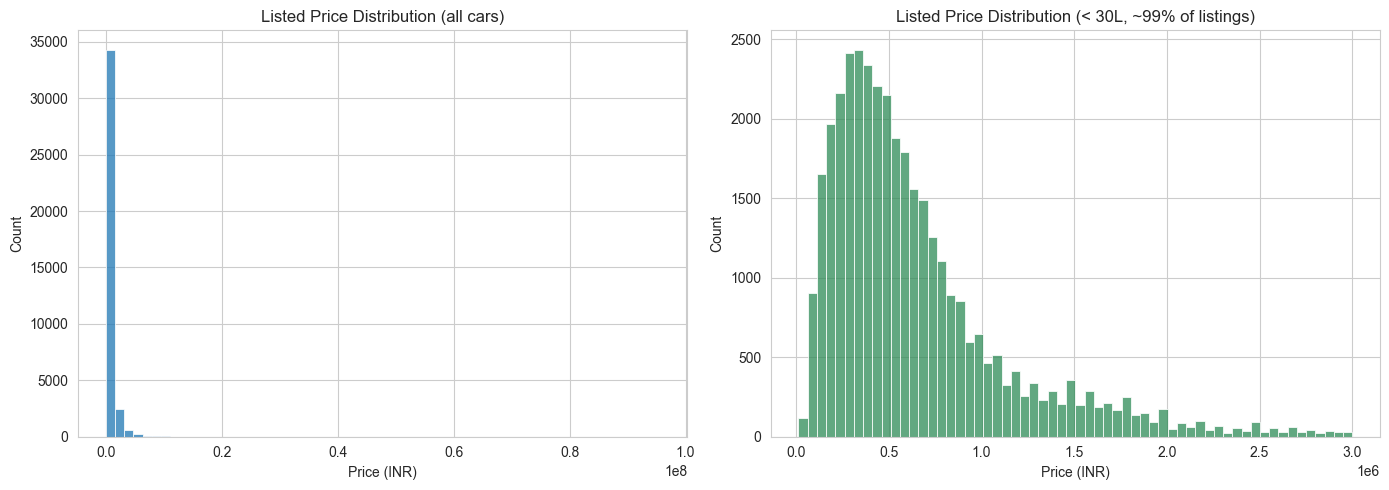

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['listed_price'], bins=60, ax=axes[0])
axes[0].set_title('Listed Price Distribution (all cars)')
axes[0].set_xlabel('Price (INR)')

sns.histplot(df[df['listed_price'] < 3_000_000]['listed_price'], bins=60, ax=axes[1], color='seagreen')
axes[1].set_title('Listed Price Distribution (< 30L, ~99% of listings)')
axes[1].set_xlabel('Price (INR)')

plt.tight_layout()
plt.show()

### 3.2 Average price by brand (top 15 by listing volume)

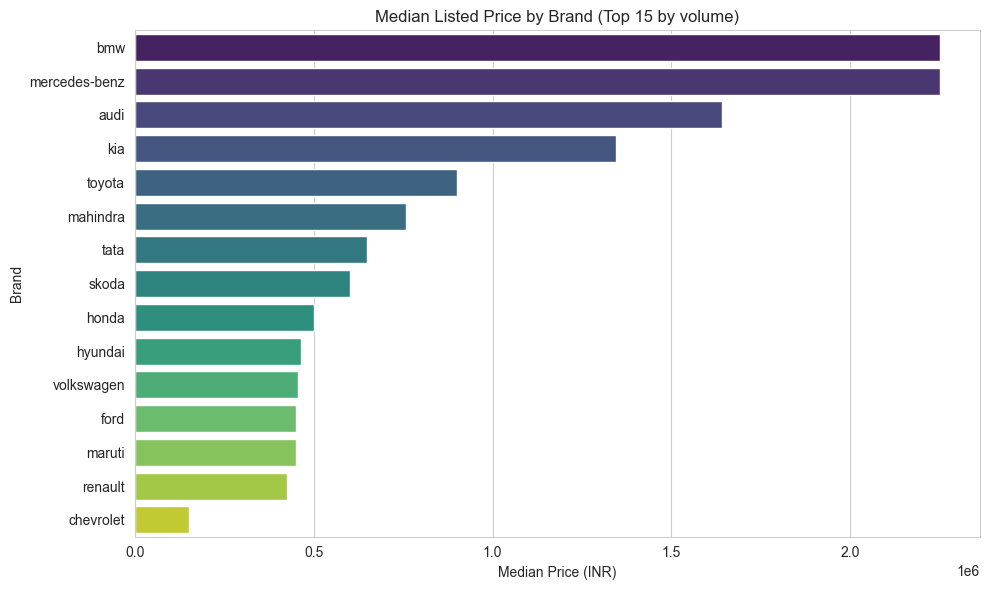

In [8]:
top_brands = df['oem'].value_counts().head(15).index
brand_price = df[df['oem'].isin(top_brands)].groupby('oem')['listed_price'].median().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=brand_price.values, y=brand_price.index, hue=brand_price.index, palette='viridis', legend=False)
plt.title('Median Listed Price by Brand (Top 15 by volume)')
plt.xlabel('Median Price (INR)')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

### 3.3 Depreciation curve — price vs. age

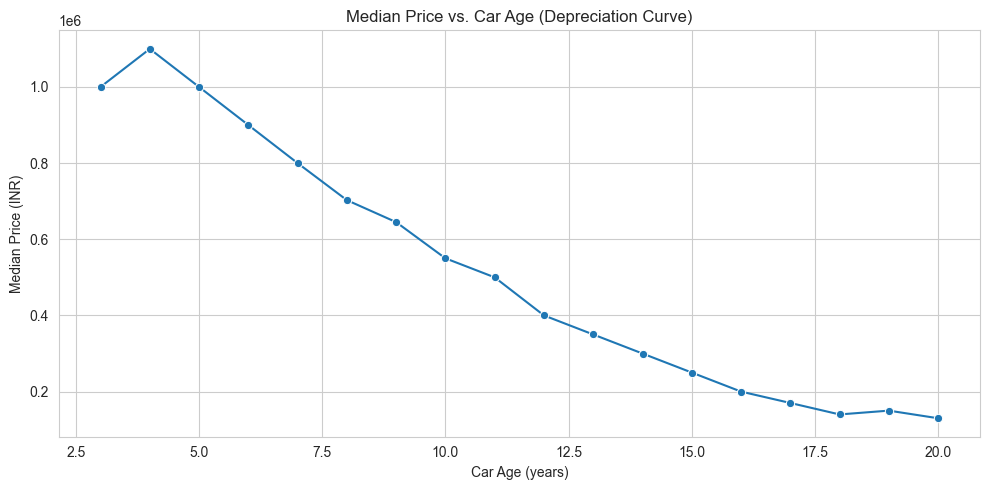

In [9]:
age_price = df.groupby('car_age')['listed_price'].median().reset_index()
age_price = age_price[age_price['car_age'] <= 20]

plt.figure(figsize=(10, 5))
sns.lineplot(data=age_price, x='car_age', y='listed_price', marker='o')
plt.title('Median Price vs. Car Age (Depreciation Curve)')
plt.xlabel('Car Age (years)')
plt.ylabel('Median Price (INR)')
plt.tight_layout()
plt.show()

### 3.4 Price vs. km driven

In [13]:
!pip install statsmodels


[notice] A new release of pip is available: 26.0.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


RuntimeError: `lowess=True` requires statsmodels, an optional dependency, to be installed.

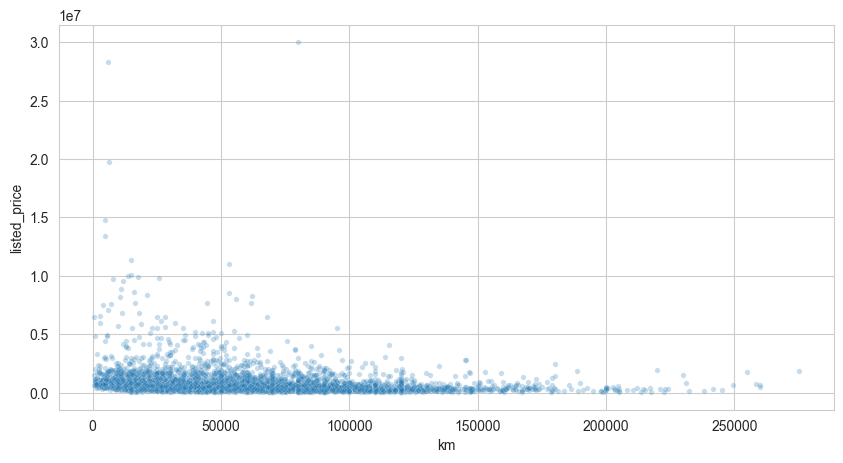

In [15]:
sample = df[df['km'] < 300_000].sample(min(5000, len(df)), random_state=42)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=sample, x='km', y='listed_price', alpha=0.25, s=15)
sns.regplot(data=sample, x='km', y='listed_price', scatter=False, color='red', lowess=True)
plt.title('Listed Price vs. Kilometers Driven')
plt.xlabel('Kilometers Driven')
plt.ylabel('Price (INR)')
plt.tight_layout()
plt.show()

### 3.5 Fuel type & transmission mix

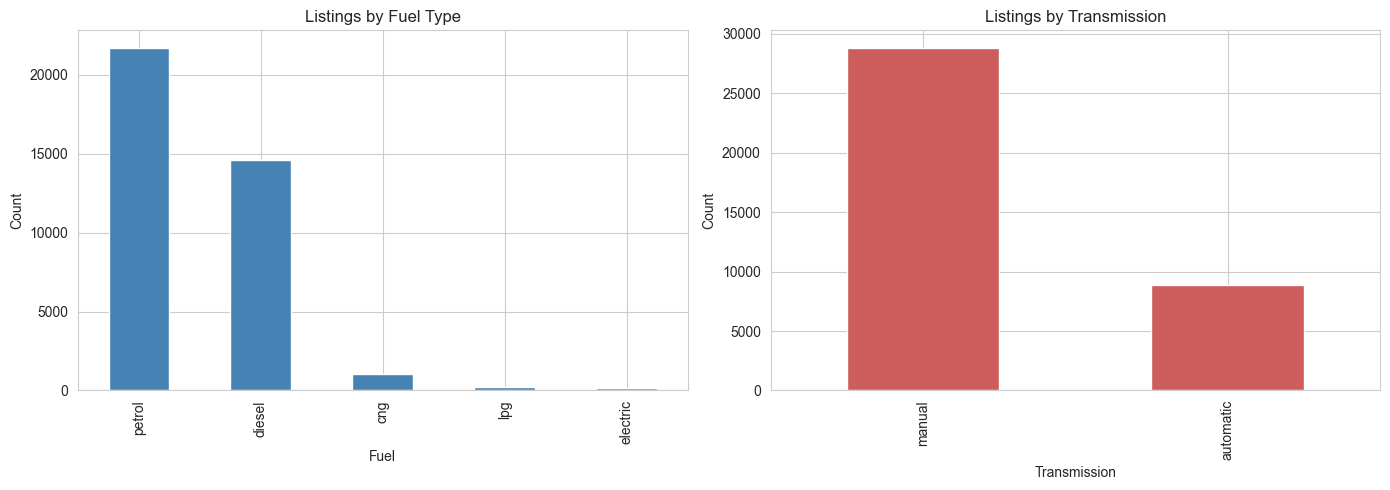

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['fuel'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Listings by Fuel Type')
axes[0].set_xlabel('Fuel')
axes[0].set_ylabel('Count')

df['transmission'].value_counts().plot(kind='bar', ax=axes[1], color='indianred')
axes[1].set_title('Listings by Transmission')
axes[1].set_xlabel('Transmission')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### 3.6 Discount % by brand (top 15 by volume)

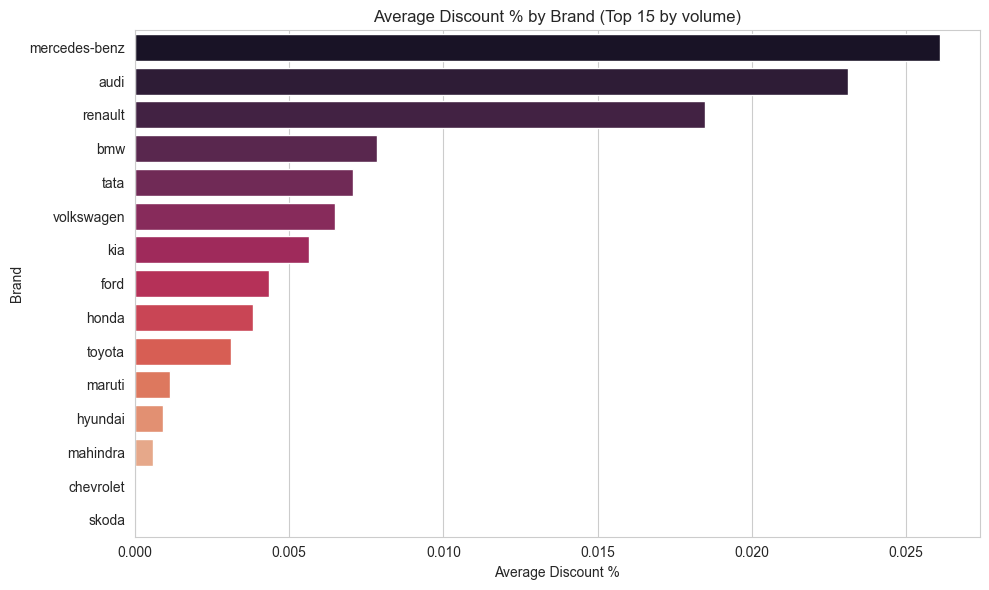

In [17]:
brand_discount = df[df['oem'].isin(top_brands)].groupby('oem')['discount_pct'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=brand_discount.values, y=brand_discount.index, hue=brand_discount.index, palette='rocket', legend=False)
plt.title('Average Discount % by Brand (Top 15 by volume)')
plt.xlabel('Average Discount %')
plt.ylabel('Brand')
plt.tight_layout()
plt.show()

### 3.7 Correlation of numeric features with price

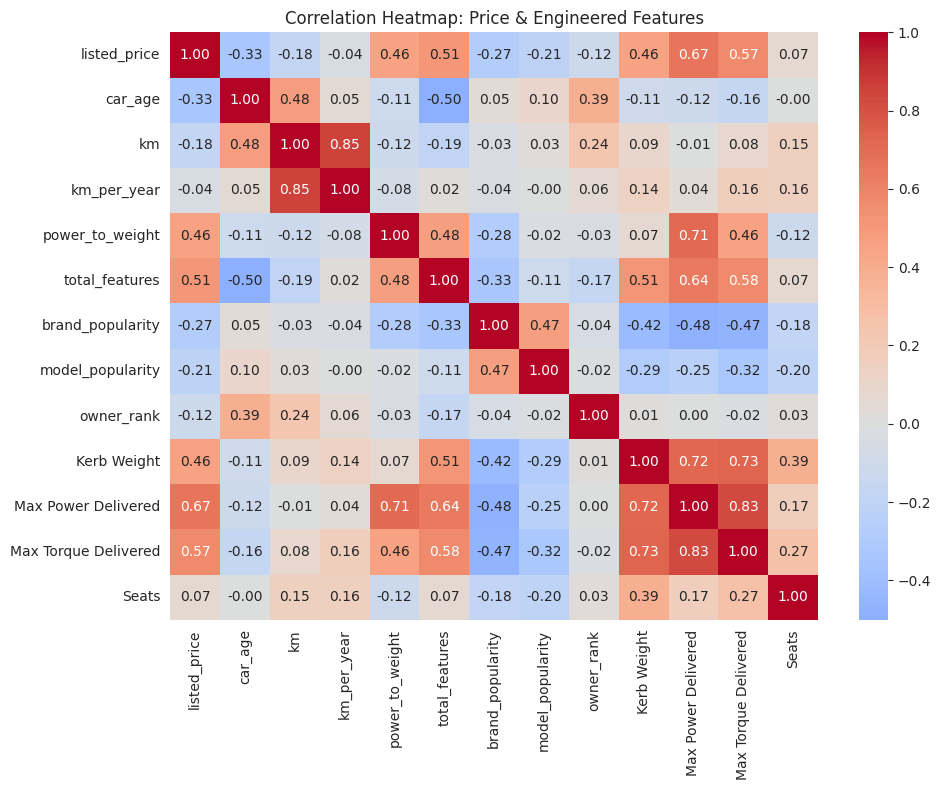

listed_price            1.000000
Max Power Delivered     0.667868
Max Torque Delivered    0.573573
total_features          0.512214
Kerb Weight             0.459216
power_to_weight         0.457249
Seats                   0.066759
km_per_year            -0.042101
owner_rank             -0.122382
km                     -0.176152
model_popularity       -0.208200
brand_popularity       -0.272651
car_age                -0.325087
Name: listed_price, dtype: float64

In [12]:
corr_cols = ['listed_price', 'car_age', 'km', 'km_per_year', 'power_to_weight',
             'total_features', 'brand_popularity', 'model_popularity', 'owner_rank',
             'Kerb Weight', 'Max Power Delivered', 'Max Torque Delivered', 'Seats']

corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap: Price & Engineered Features')
plt.tight_layout()
plt.show()

corr['listed_price'].sort_values(ascending=False)

### 3.8 Top 10 models by listing volume

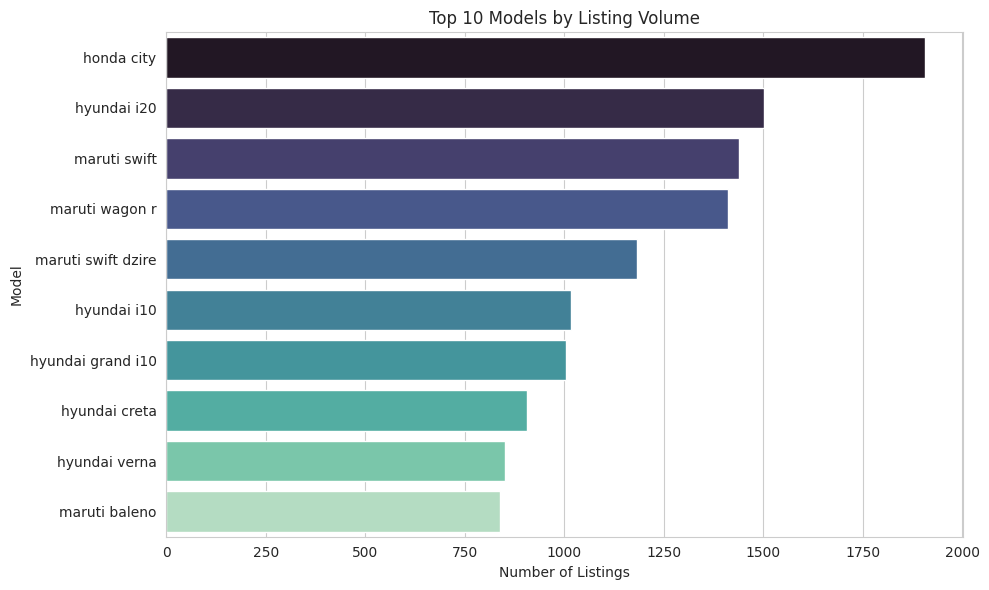

In [13]:
top_models = df['model'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_models.values, y=top_models.index, hue=top_models.index, palette='mako', legend=False)
plt.title('Top 10 Models by Listing Volume')
plt.xlabel('Number of Listings')
plt.ylabel('Model')
plt.tight_layout()
plt.show()

### 3.9 Average price: metro vs. non-metro

city_tier
metro        550000.0
non-metro    458000.0
Name: listed_price, dtype: float64


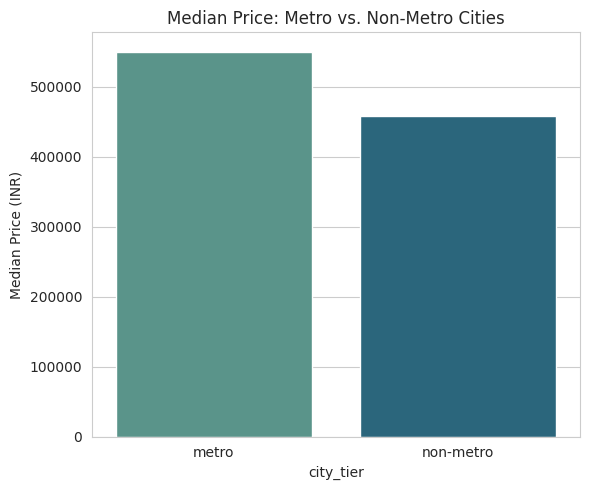

In [14]:
tier_price = df.groupby('city_tier')['listed_price'].median()
print(tier_price)

plt.figure(figsize=(6, 5))
sns.barplot(x=tier_price.index, y=tier_price.values, hue=tier_price.index, palette='crest', legend=False)
plt.title('Median Price: Metro vs. Non-Metro Cities')
plt.ylabel('Median Price (INR)')
plt.tight_layout()
plt.show()

### 3.10 Price by ownership history

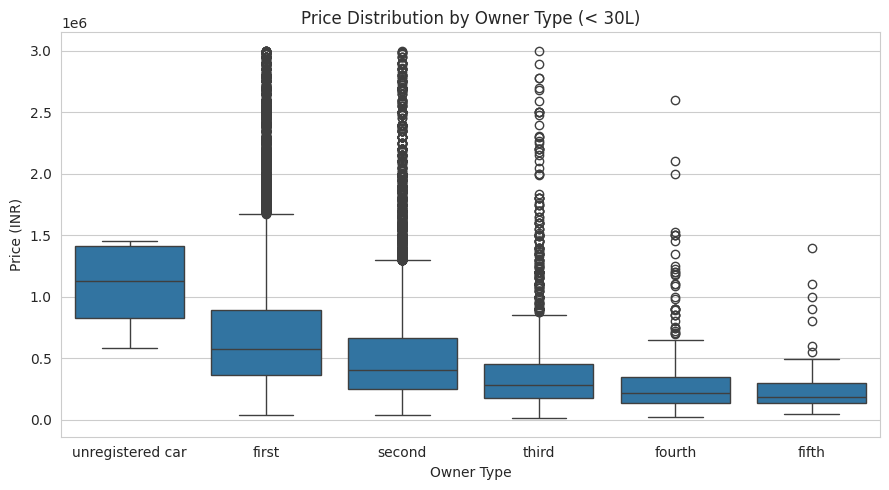

In [15]:
plt.figure(figsize=(9, 5))
order = ['unregistered car', 'first', 'second', 'third', 'fourth', 'fifth']
order = [o for o in order if o in df['owner_type'].unique()]
sns.boxplot(data=df[df['listed_price'] < 3_000_000], x='owner_type', y='listed_price', order=order)
plt.title('Price Distribution by Owner Type (< 30L)')
plt.xlabel('Owner Type')
plt.ylabel('Price (INR)')
plt.tight_layout()
plt.show()

## 4. Save feature-engineered dataset

In [16]:
df.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH)
print("Shape:", df.shape)
new_cols = ['car_age', 'km_per_year', 'power_to_weight', 'discount_pct',
            'num_top_features', 'num_comfort_features', 'num_interior_features',
            'num_exterior_features', 'num_safety_features', 'total_features',
            'is_luxury_brand', 'is_automatic', 'is_diesel', 'owner_rank',
            'brand_popularity', 'model_popularity', 'city_tier']
print("\nNew engineered columns:", new_cols)

Saved: car_data_features.csv
Shape: (37708, 74)

New engineered columns: ['car_age', 'km_per_year', 'power_to_weight', 'discount_pct', 'num_top_features', 'num_comfort_features', 'num_interior_features', 'num_exterior_features', 'num_safety_features', 'total_features', 'is_luxury_brand', 'is_automatic', 'is_diesel', 'owner_rank', 'brand_popularity', 'model_popularity', 'city_tier']
